load libraries

In [2]:
import pandas as pd 
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.dummy import DummyClassifier   
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve
from pathlib import Path
VISUALS_DIR = Path("outputs/visualizations")
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

Task 1: Data Exploration and Visualization

the data dimention (1101, 12)
the column name: Index(['customer_id', 'tenure_months', 'monthly_bill', 'support_tickets_90d',
       'late_payments_6m', 'contract_type', 'auto_pay', 'internet_type',
       'weekly_usage_gb', 'region', 'case_status', 'churned_next_month'],
      dtype='str')
the data type for each column: customer_id                str
tenure_months          float64
monthly_bill           float64
support_tickets_90d      int64
late_payments_6m       float64
contract_type              str
auto_pay                   str
internet_type              str
weekly_usage_gb        float64
region                     str
case_status                str
churned_next_month       int64
dtype: object
first rows   customer_id  tenure_months  monthly_bill  support_tickets_90d  \
0      C00963           49.0         90.18                    1   
1      C01063           57.0         87.50                    1   
2      C00198           60.0         46.73                    1   
3      C00635

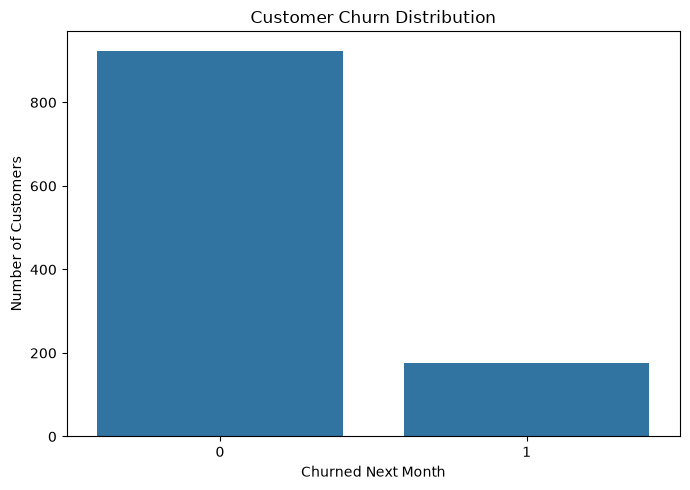

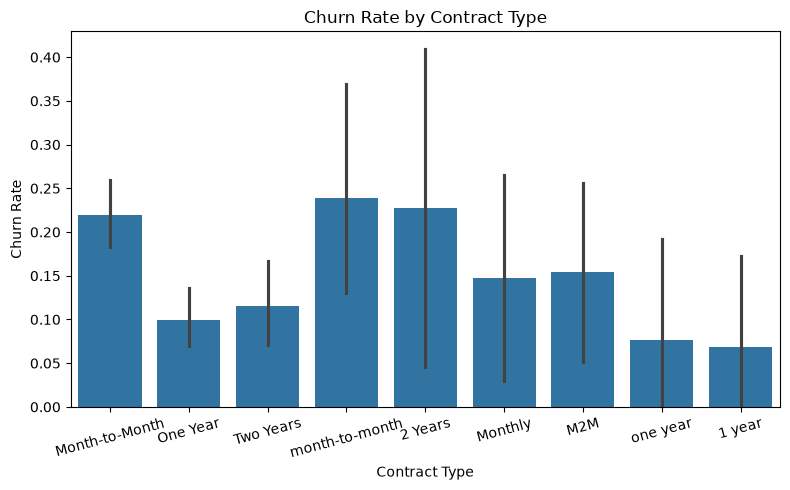

the missing values for each column: customer_id             0
tenure_months          47
monthly_bill           58
support_tickets_90d     0
late_payments_6m       24
contract_type           0
auto_pay               51
internet_type          35
weekly_usage_gb        76
region                  0
case_status             0
churned_next_month      0
dtype: int64
the duplicated rows: 21
the negative tenure months: 7
the negative weekly usage gb: 5
the unique values for contract_type: <StringArray>
['Month-to-Month',       'One Year',      'Two Years', 'month-to-month',
        '2 Years',        'Monthly',            'M2M',       'one year',
         '1 year']
Length: 9, dtype: str
the unique values for auto_pay: <StringArray>
['No', 'Yes', 'no', 'yes', 'Y', '1', nan, '0', 'N']
Length: 9, dtype: str
the unique values for internet_type: <StringArray>
['Fiber', 'fiber', '5G', 'DSL', nan]
Length: 5, dtype: str
the unique values for region: <StringArray>
['South', 'North', 'Central', 'central ']

In [3]:
#task1
train_data=pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\SDK\data\train.csv")
print("the data dimention",train_data.shape)
print("the column name:",train_data.columns)
print("the data type for each column:",train_data.dtypes)
print("first rows",train_data.head())
#======================================================================selecting the numerical and categorical features
identifier=train_data["customer_id"].name
target_feature=train_data["churned_next_month"].name
numerical_features=train_data.select_dtypes(include=['int64','float64']).columns.drop(target_feature)
categorical_features = train_data.select_dtypes(include=['str', 'object']).columns.drop(identifier)

print("the identifier feature:",identifier)
print("the numerical features:",numerical_features)
print("the categorical features:",categorical_features)
print("the target feature:",target_feature)
#======================================================================checking the target feature distribution
churned_next_month=train_data["churned_next_month"].value_counts()
print("the target feature distribution:",churned_next_month)
#======================================================================calculating the percentage of target
customer_will_churned=(len(train_data[train_data["churned_next_month"]==1])/churned_next_month.sum())*100
customer_will_not_churned=(len(train_data[train_data["churned_next_month"]==0])/churned_next_month.sum())*100
print("the percentage of customer will churned:",customer_will_churned)
print("the percentage of customer will not churned:",customer_will_not_churned)
#======================================================================visualizing the target feature distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=train_data , x="churned_next_month")
plt.title("Customer Churn Distribution")
plt.xlabel("Churned Next Month")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "churn_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

plt.figure(figsize=(8, 5))
sns.barplot(data=train_data, x="contract_type", y="churned_next_month")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "churn_by_contract.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
#========================================checking data problems
missing_values=train_data.isnull().sum()
duplicated_rows=train_data.duplicated().sum()
negative_tenure=train_data[train_data["tenure_months"]<0].shape[0]
negative_weekly_usage_gb =train_data[train_data["weekly_usage_gb"]<0].shape[0]

#categorical features checking
contract_type_values=train_data["contract_type"].unique()
auto_pay_values=train_data["auto_pay"].unique()
internet_type_values=train_data["internet_type"].unique()
region_values=train_data["region"].unique()
case_status_values=train_data["case_status"].unique()
churned_next_month_values=train_data["churned_next_month"].unique()


print("the missing values for each column:",missing_values)
print("the duplicated rows:",duplicated_rows)
print("the negative tenure months:",negative_tenure)
print("the negative weekly usage gb:",negative_weekly_usage_gb)
print("the unique values for contract_type:",contract_type_values)
print("the unique values for auto_pay:",auto_pay_values)
print("the unique values for internet_type:",internet_type_values)
print("the unique values for region:",region_values)
print("the unique values for case_status:",case_status_values)
print("the unique values for churned_next_month:",churned_next_month_values)

conclusion
In this task, I explored the dataset to understand its structure, features, and data quality. The dataset contains 1,101 rows and 12 columns. I identified the numerical and categorical features and checked the target variable churned_next_month. The results showed that 83.92% of customers stayed with the company, while 16.08% left, which indicates that the dataset is imbalanced. I created two visualizations to show the target distribution and compare churn rates across contract types. The contract type values were not consistent, as some categories had different names or letter cases but represented the same type of contract. I also found 21 duplicate records, missing values in several columns, 7 negative values in tenure_months, and 5 negative values in weekly_usage_gb. These issues may affect model performance, so they need to be handled during data cleaning and preprocessing. Due to the class imbalance, I will use multiple evaluation metrics to check how well the models identify customers who may leave the company.

Task 2: Data Cleaning, Preprocessing, and Splitting

In [4]:
#=========================================data cleaning
#removing the duplicated rows
cleaned_df=train_data.copy()
cleaned_df=cleaned_df.drop_duplicates()
print("the shape of the data after removing the duplicated rows:",cleaned_df.shape)
#standardizing the categorical features
cleaned_df["region"]=cleaned_df["region"].str.strip().str.lower()
cleaned_df["internet_type"]=cleaned_df["internet_type"].str.strip().str.lower()
cleaned_df["auto_pay"]=cleaned_df["auto_pay"].str.strip().str.lower().replace({"1": "yes","y": "yes","0": "no","n": "no"})
cleaned_df["contract_type"]=cleaned_df["contract_type"].str.strip().str.lower().replace({"1 year": "one year","2 years": "two years","m2m": "month-to-month","monthly": "month-to-month"}   )
print("the unique values for contract_type after standardization:",cleaned_df["contract_type"].unique())
print("the unique values for auto_pay after standardization:",cleaned_df["auto_pay"].unique())
print("the unique values for internet_type after standardization:",cleaned_df["internet_type"].unique())
print("the unique values for region after standardization:",cleaned_df["region"].unique())
# cleaning invalid values for tenure_months and weekly_usage_gb
print("the values of tenure_months less than 0:",cleaned_df[cleaned_df["tenure_months"]<0])
print("the values of weekly_usage_gb less than 0:",cleaned_df[cleaned_df["weekly_usage_gb"]<0])
cleaned_df.loc[cleaned_df["tenure_months"]<0, "tenure_months"]=np.nan
cleaned_df.loc[cleaned_df["weekly_usage_gb"] < 0, "weekly_usage_gb"] = np.nan
#invalid values became nan values


# checking the missing values
columns_with_missing_values = cleaned_df.columns[cleaned_df.isnull().any()]
def check_missing_values(columns_with_missing_values):
    for col in columns_with_missing_values:
        missing_count = cleaned_df[col].isnull().sum()
        missing_percentage = (missing_count / len(cleaned_df)) * 100
        print(f"Column '{col}' has {missing_count} missing values ({missing_percentage:.2f}%).")
        if cleaned_df[col].dtype == 'int64' or cleaned_df[col].dtype == 'float64':
                print(f"Column '{col}' min: {cleaned_df[col].min()}, max: {cleaned_df[col].max()}")
                print(f"Column '{col}' quantiles:\n{cleaned_df[col].quantile([0.25, 0.5, 0.75])}")
        else:
                print(f"Column '{col}' counts:\n{cleaned_df[col].value_counts()}")
check_missing_values(columns_with_missing_values)

print("iqr for monthly_bill:",cleaned_df["monthly_bill"].quantile(0.75)-cleaned_df["monthly_bill"].quantile(0.25))
upper_limit = cleaned_df["monthly_bill"].quantile(0.75)+1.5*(cleaned_df["monthly_bill"].quantile(0.75)-cleaned_df["monthly_bill"].quantile(0.25))
print('upper limit for monthly_bill:', upper_limit)
#for monthly_bill, the upper limit is 113.90625, and the maximum value is 1001.13, which is greater than the upper limit, indicating that there are outliers in the monthly_bill column.
#required features for the model
cleaned_df.loc[ cleaned_df["monthly_bill"] > 113.90625,"monthly_bill"].sort_values(ascending=False)

outliers = cleaned_df[cleaned_df["monthly_bill"] > upper_limit]
print("Number of records above upper_limit:", len(outliers))
print("\nRecords above upper_limit:")
print( outliers[["customer_id", "monthly_bill"]].sort_values(by="monthly_bill", ascending=False))


#=================================================splitting the data into train and Vvalidation sets
input_features = ['tenure_months', 'weekly_usage_gb', 'contract_type', 'auto_pay', 'internet_type', 'region',"monthly_bill","support_tickets_90d","late_payments_6m"]
target_feature = 'churned_next_month'
train_data, validation_data = train_test_split(cleaned_df, test_size=0.2, random_state=42, stratify=cleaned_df[target_feature])
x_train,x_validation=train_data[input_features],validation_data[input_features]
y_train,y_validation=train_data[target_feature],validation_data[target_feature]


#===============================================preprocessing the data
def preprocess_data(x_train, x_validation):
    numerical_features = ['tenure_months', 'weekly_usage_gb','support_tickets_90d', 'late_payments_6m']
    categorical_features = ['contract_type', 'auto_pay', 'internet_type', 'region']
    numerical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
    bill_upper_limit = x_train['monthly_bill'].quantile(0.75) + 1.5 * (x_train['monthly_bill'].quantile(0.75) - x_train['monthly_bill'].quantile(0.25))
    categorical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('onehot', OneHotEncoder(handle_unknown='ignore'))])

    monthly_bill_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('cap', FunctionTransformer(lambda x: np.clip(x, None, bill_upper_limit),feature_names_out='one-to-one'))])
    preprocessor = ColumnTransformer(transformers=[('num', numerical_transformer, numerical_features), ('bill', monthly_bill_transformer, ['monthly_bill']), ('cat', categorical_transformer, categorical_features)])
    x_train_processed = preprocessor.fit_transform(x_train)
    x_validation_processed = preprocessor.transform(x_validation)

    return x_train_processed, x_validation_processed, preprocessor
x_train_processed, x_validation_processed, preprocessor = preprocess_data(x_train, x_validation)
print("Training shape:", x_train_processed.shape)
print("Validation shape:", x_validation_processed.shape)
print("Same number of columns:",x_train_processed.shape[1] == x_validation_processed.shape[1])
print("Missing values in training:", np.isnan(x_train_processed).sum())
print("Missing values in validation:", np.isnan(x_validation_processed).sum())

print("Training max monthly_bill:",
      preprocessor.named_transformers_['bill'].transform(
          x_train[['monthly_bill']]
      ).max())

print("Validation max monthly_bill:",
      preprocessor.named_transformers_['bill'].transform(
          x_validation[['monthly_bill']]
      ).max())

the shape of the data after removing the duplicated rows: (1080, 12)
the unique values for contract_type after standardization: <StringArray>
['month-to-month', 'one year', 'two years']
Length: 3, dtype: str
the unique values for auto_pay after standardization: <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
the unique values for internet_type after standardization: <StringArray>
['fiber', '5g', 'dsl', nan]
Length: 4, dtype: str
the unique values for region after standardization: <StringArray>
['south', 'north', 'central']
Length: 3, dtype: str
the values of tenure_months less than 0:      customer_id  tenure_months  monthly_bill  support_tickets_90d  \
18        C00858           -2.0         49.91                    1   
38        C00087           -2.0         65.02                    3   
52        C01180           -2.0         85.33                    2   
525       C01094           -2.0         33.29                    3   
916       C01109           -2.0         51.33      

conclusion2
In this task, I cleaned and prepared the dataset for model training. I removed 21 duplicate records, reducing the dataset from 1,101 to 1,080 rows. I standardized categorical values in contract_type, auto_pay, internet_type, and region to make the categories consistent. I also identified negative values in tenure_months and handled invalid values during preprocessing. Missing values were handled using imputation, and outliers in monthly_bill were limited using an upper limit calculated from the training data. I then split the cleaned data into training and validation sets. The preprocessing steps were fitted on the training data and applied to the validation data to avoid data leakage. After preprocessing, both sets contained no missing values, and the maximum monthly_bill value was limited to approximately 113.16.


Task 3: Model Training, Comparison, and Tuning

In [5]:
#===============================================training
#building a baseline model
baseline_model = DummyClassifier(strategy='most_frequent', random_state=42)
baseline_model.fit(x_train_processed, y_train)
y_pred = baseline_model.predict(x_validation_processed)

accuracy = accuracy_score(y_validation, y_pred)
precision = precision_score(y_validation, y_pred, zero_division=0)
recall = recall_score(y_validation, y_pred, zero_division=0)
f1 = f1_score(y_validation, y_pred, zero_division=0)
cm = confusion_matrix(y_validation, y_pred, labels=[0, 1])

print("Baseline Model Performance:")
print("Accuracy:", accuracy)
print("Precision:",precision)
print("Recall:", recall)
print("F1 Score:",f1)
print("Confusion Matrix:")
print(cm)

#logistic regression model
logistic_model = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=1000, random_state=42))])
logistic_model.fit(x_train, y_train)    
logistic_y_pred = logistic_model.predict(x_validation)
logistic_accuracy = accuracy_score(y_validation, logistic_y_pred)
logistic_precision = precision_score(y_validation, logistic_y_pred, zero_division=0)
logistic_recall = recall_score(y_validation, logistic_y_pred, zero_division=0)
logistic_f1 = f1_score(y_validation, logistic_y_pred, zero_division=0)
logistic_y_proba = logistic_model.predict_proba(x_validation)[:, 1]
logistic_pr_auc = average_precision_score(y_validation, logistic_y_proba)


print("\nLogistic Regression Model Performance:")
print("Accuracy:", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall:", logistic_recall)
print("F1 Score:", logistic_f1)
print("PR-AUC:", logistic_pr_auc)
print("Confusion Matrix:")
print(confusion_matrix(y_validation, logistic_y_pred, labels=[0, 1]))

#random forest model
random_forest_model = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(random_state=42))])
random_forest_model.fit(x_train, y_train)   
random_forest_y_pred = random_forest_model.predict(x_validation)
random_forest_accuracy = accuracy_score(y_validation, random_forest_y_pred) 
random_forest_precision = precision_score(y_validation, random_forest_y_pred, zero_division=0)
random_forest_recall = recall_score(y_validation, random_forest_y_pred, zero_division=0)
random_forest_f1 = f1_score(y_validation, random_forest_y_pred, zero_division=0)
rf_y_proba = random_forest_model.predict_proba(x_validation)[:, 1]
rf_pr_auc = average_precision_score(y_validation, rf_y_proba)

print("\nRandom Forest Model Performance:") 
print("Accuracy:", random_forest_accuracy)
print("Precision:", random_forest_precision)    
print("Recall:", random_forest_recall)
print("F1 Score:", random_forest_f1)
print("PR-AUC:", rf_pr_auc)
print("Confusion Matrix:")
print(confusion_matrix(y_validation, random_forest_y_pred, labels=[0, 1]))



Baseline Model Performance:
Accuracy: 0.8425925925925926
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
Confusion Matrix:
[[182   0]
 [ 34   0]]

Logistic Regression Model Performance:
Accuracy: 0.8379629629629629
Precision: 0.42857142857142855
Recall: 0.08823529411764706
F1 Score: 0.14634146341463414
PR-AUC: 0.44722020655591205
Confusion Matrix:
[[178   4]
 [ 31   3]]

Random Forest Model Performance:
Accuracy: 0.8611111111111112
Precision: 0.8333333333333334
Recall: 0.14705882352941177
F1 Score: 0.25
PR-AUC: 0.3918418707691049
Confusion Matrix:
[[181   1]
 [ 29   5]]


conclusion 3
In this task, I trained and evaluated three models: a Dummy Classifier as a baseline, Logistic Regression, and Random Forest. The baseline model achieved an accuracy of 84.26%, but its precision, recall, and F1-score were all 0 because it predicted every customer as a non-churner. Logistic Regression achieved an accuracy of 83.80%, a precision of 42.86%, a recall of 8.82%, an F1-score of 14.63%, and a PR-AUC of 0.4472. Random Forest achieved an accuracy of 86.11%, a precision of 83.33%, a recall of 14.71%, an F1-score of 25.00%, and a PR-AUC of 0.3918. Random Forest had the highest accuracy and precision among the trained models, but both Logistic Regression and Random Forest missed many customers who actually churned. These results show that accuracy alone is not enough to evaluate performance because the dataset is imbalanced. Further hyperparameter tuning is needed to improve the models' ability to identify customers at risk of churn and compare their performance using appropriate metrics.

Task4: Tuning model

In [14]:
#Logistic Regression tuning

logistic_param_grid = {'classifier__C': [0.01, 0.1, 1, 10], 'classifier__solver': ['liblinear', 'lbfgs']}
logistic_model_tuned = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))])
logistic_grid = GridSearchCV(logistic_model_tuned, param_grid=logistic_param_grid, scoring='average_precision', cv=5, n_jobs=-1)
logistic_grid.fit(x_train, y_train)
logistic_model_tuned = logistic_grid.best_estimator_
logistic_y_pred_tuned = logistic_model_tuned.predict(x_validation)
logistic_y_proba_tuned = logistic_model_tuned.predict_proba(x_validation)[:, 1]
logistic_accuracy_tuned = accuracy_score(y_validation, logistic_y_pred_tuned)
logistic_precision_tuned = precision_score(y_validation, logistic_y_pred_tuned, zero_division=0)
logistic_recall_tuned = recall_score(y_validation, logistic_y_pred_tuned, zero_division=0)
logistic_f1_tuned = f1_score(y_validation, logistic_y_pred_tuned, zero_division=0)
logistic_pr_auc_tuned = average_precision_score(y_validation, logistic_y_proba_tuned)
print("\nLogistic Regression Tuned Model Performance:")
print("Best Parameters:", logistic_grid.best_params_)
print("Accuracy:", logistic_accuracy_tuned)
print("Precision:", logistic_precision_tuned)
print("Recall:", logistic_recall_tuned)
print("F1 Score:", logistic_f1_tuned)
print("PR-AUC:", logistic_pr_auc_tuned)
print("Confusion Matrix:")
print(confusion_matrix(y_validation, logistic_y_pred_tuned, labels=[0, 1]))





Logistic Regression Tuned Model Performance:
Best Parameters: {'classifier__C': 10, 'classifier__solver': 'liblinear'}
Accuracy: 0.7407407407407407
Precision: 0.3333333333333333
Recall: 0.6470588235294118
F1 Score: 0.44
PR-AUC: 0.45320607948120173
Confusion Matrix:
[[138  44]
 [ 12  22]]


In [15]:
thresholds = [0.3, 0.4, 0.5, 0.6]
for threshold in thresholds:
    y_pred_threshold = (logistic_y_proba_tuned >= threshold).astype(int)
    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_validation, y_pred_threshold, zero_division=0))
    print("Recall:", recall_score(y_validation, y_pred_threshold, zero_division=0))
    print("F1-score:", f1_score(y_validation, y_pred_threshold, zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(y_validation, y_pred_threshold))



Threshold: 0.3
Precision: 0.23308270676691728
Recall: 0.9117647058823529
F1-score: 0.3712574850299401
Confusion Matrix:
 [[ 80 102]
 [  3  31]]

Threshold: 0.4
Precision: 0.24509803921568626
Recall: 0.7352941176470589
F1-score: 0.36764705882352944
Confusion Matrix:
 [[105  77]
 [  9  25]]

Threshold: 0.5
Precision: 0.3333333333333333
Recall: 0.6470588235294118
F1-score: 0.44
Confusion Matrix:
 [[138  44]
 [ 12  22]]

Threshold: 0.6
Precision: 0.4090909090909091
Recall: 0.5294117647058824
F1-score: 0.46153846153846156
Confusion Matrix:
 [[156  26]
 [ 16  18]]


In [11]:
#random Forest tuning

rf_param_grid = {'classifier__n_estimators': [100, 200], 'classifier__max_depth': [None, 10, 20], 'classifier__min_samples_split': [2, 5], 'classifier__min_samples_leaf': [1, 2]}
random_forest_model_tuned = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))])
rf_grid = GridSearchCV(random_forest_model_tuned, param_grid=rf_param_grid, scoring='average_precision', cv=5, n_jobs=-1)
rf_grid.fit(x_train, y_train)
random_forest_model_tuned = rf_grid.best_estimator_
rf_y_pred_tuned = random_forest_model_tuned.predict(x_validation)
rf_y_proba_tuned = random_forest_model_tuned.predict_proba(x_validation)[:, 1]
rf_accuracy_tuned = accuracy_score(y_validation, rf_y_pred_tuned)
rf_precision_tuned = precision_score(y_validation, rf_y_pred_tuned, zero_division=0)
rf_recall_tuned = recall_score(y_validation, rf_y_pred_tuned, zero_division=0)
rf_f1_tuned = f1_score(y_validation, rf_y_pred_tuned, zero_division=0)
rf_pr_auc_tuned = average_precision_score(y_validation, rf_y_proba_tuned)
print("\nRandom Forest Tuned Model Performance:")
print("Best Parameters:", rf_grid.best_params_)
print("Accuracy:", rf_accuracy_tuned)
print("Precision:", rf_precision_tuned)
print("Recall:", rf_recall_tuned)
print("F1 Score:", rf_f1_tuned)
print("PR-AUC:", rf_pr_auc_tuned)
print("Confusion Matrix:")
print(confusion_matrix(y_validation, rf_y_pred_tuned, labels=[0, 1]))


Random Forest Tuned Model Performance:
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Accuracy: 0.8240740740740741
Precision: 0.4166666666666667
Recall: 0.29411764705882354
F1 Score: 0.3448275862068966
PR-AUC: 0.4410211657969728
Confusion Matrix:
[[168  14]
 [ 24  10]]


coclusion 4
In this task, I evaluated the models using accuracy, precision, recall, F1-score, PR-AUC, and confusion matrices. The baseline model achieved 84.26% accuracy but failed to identify any customers who churned, resulting in zero recall and F1-score. The original Logistic Regression model achieved 8.82% recall and a 14.63% F1-score, while the original Random Forest model achieved 14.71% recall and a 25.00% F1-score.

After tuning Logistic Regression using GridSearchCV, the model achieved 74.07% accuracy, 33.33% precision, 64.71% recall, a 44.00% F1-score, and a PR-AUC of 0.4532. Its confusion matrix showed 138 true negatives, 44 false positives, 12 false negatives, and 22 true positives. The tuned Random Forest model achieved 82.41% accuracy, 41.67% precision, 29.41% recall, a 34.48% F1-score, and a PR-AUC of 0.4410. Its confusion matrix showed 168 true negatives, 14 false positives, 24 false negatives, and 10 true positives.

The tuned Logistic Regression model achieved higher recall and F1-score, meaning it identified more customers who churned, but it also produced more false positives. The tuned Random Forest model had higher accuracy and precision and fewer false positives, but it missed more customers who churned. Since the dataset is imbalanced, accuracy alone is not sufficient to evaluate the models. Recall is important when the goal is to identify as many potential churners as possible, while precision is useful when unnecessary customer-retention actions are costly. Based on the current validation results, tuned Logistic Regression is the stronger choice when identifying potential churners is the main priority, while tuned Random Forest may be preferable when reducing false alarms is more important.

Task 5:Test Predictions and CSV Export

In [ ]:
#================================================== creating test predictions
test_data = pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\SDK\data\test.csv")
test_data["region"] = test_data["region"].str.strip().str.lower()
test_data["internet_type"] = test_data["internet_type"].str.strip().str.lower()
test_data["auto_pay"] = test_data["auto_pay"].str.strip().str.lower().replace({"1": "yes", "y": "yes", "0": "no", "n": "no"})
test_data["contract_type"] = test_data["contract_type"].str.strip().str.lower().replace({"1 year": "one year", "2 years": "two years", "m2m": "month-to-month", "monthly": "month-to-month"})
test_data.loc[test_data["tenure_months"] < 0, "tenure_months"] = np.nan
test_data.loc[test_data["weekly_usage_gb"] < 0, "weekly_usage_gb"] = np.nan
test_probabilities = logistic_model_tuned.predict_proba(test_data[input_features])[:, 1]
test_predictions = (test_probabilities >= 0.6).astype(int)
submission = pd.DataFrame({
    "customer_id": test_data["customer_id"],
    "churn_probability": np.round(test_probabilities, 2),
    "churn_prediction": test_predictions
})
submission.to_csv("outputs/test_predictions.csv", index=False)
print(submission.head())
print("Predictions file shape:", submission.shape)

  customer_id  churn_probability  churn_prediction
0      C00513           0.459751                 0
1      C00066           0.227757                 0
2      C00865           0.233891                 0
3      C00899           0.718590                 1
4      C00368           0.338947                 0
Predictions file shape: (270, 3)
